In [1]:
import pandas as pd
import numpy as np
import lightgbm as lgb
import joblib
import os, gc
from pathlib import Path
import matplotlib.pyplot as plt

DATA_DIR  = Path("../data/processed")
MODEL_DIR = Path("../models")
IMG_DIR   = Path("../docs/img")
MODEL_DIR.mkdir(exist_ok=True, parents=True)

TRAIN_END = pd.Timestamp("2016-03-27")
VAL_END   = pd.Timestamp("2016-04-24")
TEST_END  = pd.Timestamp("2016-05-22")
HORIZON   = 28

# 5 quantiles — extend to 7 (add 0.005, 0.995) later if you want tighter tails
QUANTILES = [0.025, 0.25, 0.50, 0.75, 0.975]

print("Imports OK")

Imports OK


In [2]:
features_path = DATA_DIR / "features.parquet"
assert features_path.exists(), "Missing features.parquet — run notebook 03 prerequisites first."

df = pd.read_parquet(features_path)
df = df.sort_values(["item_id","store_id","date"]).reset_index(drop=True)

feature_cols = [
    "wday","month","year","wm_yr_wk","snap_ca","snap_tx","snap_wi",
    "sell_price","price_pct_change",
    "lag_7","lag_28","roll7_mean","roll28_mean","roll7_std",
    "item_id","store_id","dept_id","cat_id","state_id",
    "event_name_1","event_type_1",
]
cat_cols = ["item_id","store_id","dept_id","cat_id","state_id",
            "event_name_1","event_type_1"]

train_mask = df["date"] <= TRAIN_END
val_mask   = (df["date"] > TRAIN_END) & (df["date"] <= VAL_END)
test_mask  = (df["date"] > VAL_END)   & (df["date"] <= TEST_END)
print(f"train: {train_mask.sum():,}  val: {val_mask.sum():,}  test: {test_mask.sum():,}")

train: 30,032,650  val: 853,720  test: 853,720


In [3]:
X_train = df.loc[train_mask, feature_cols]
y_train = df.loc[train_mask, "units_sold"]
X_val   = df.loc[val_mask,   feature_cols]
y_val   = df.loc[val_mask,   "units_sold"]
print(f"X_train: {X_train.shape}, X_val: {X_val.shape}")

X_train: (30032650, 21), X_val: (853720, 21)


In [4]:
models = {}
for q in QUANTILES:
    model_path = MODEL_DIR / f"lgbm_q{int(q*1000):03d}.pkl"
    if model_path.exists():
        print(f"q={q}: loading from {model_path.name}")
        models[q] = joblib.load(model_path)
        continue

    print(f"\n=== Training q={q} ===")
    params = dict(
        objective="quantile", alpha=q,
        metric="quantile",
        learning_rate=0.05, num_leaves=128,
        feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1,
        n_estimators=800, verbose=-1,
    )
    model = lgb.LGBMRegressor(**params)
    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        categorical_feature=cat_cols,
        callbacks=[lgb.early_stopping(30), lgb.log_evaluation(100)],
    )
    joblib.dump(model, model_path)
    models[q] = model
    print(f"q={q}: saved to {model_path.name}, best_iter={model.best_iteration_}")
    gc.collect()

print(f"\nAll {len(QUANTILES)} models ready")


=== Training q=0.025 ===
Training until validation scores don't improve for 30 rounds
Early stopping, best iteration is:
[33]	valid_0's quantile: 0.034562
q=0.025: saved to lgbm_q025.pkl, best_iter=33

=== Training q=0.25 ===
Training until validation scores don't improve for 30 rounds
[100]	valid_0's quantile: 0.281
[200]	valid_0's quantile: 0.280467
[300]	valid_0's quantile: 0.280412
[400]	valid_0's quantile: 0.280361
Early stopping, best iteration is:
[390]	valid_0's quantile: 0.280361
q=0.25: saved to lgbm_q250.pkl, best_iter=390

=== Training q=0.5 ===
Training until validation scores don't improve for 30 rounds
[100]	valid_0's quantile: 0.443507
[200]	valid_0's quantile: 0.442268
[300]	valid_0's quantile: 0.442088
[400]	valid_0's quantile: 0.441986
[500]	valid_0's quantile: 0.441864
[600]	valid_0's quantile: 0.4417
Early stopping, best iteration is:
[659]	valid_0's quantile: 0.44162
q=0.5: saved to lgbm_q500.pkl, best_iter=659

=== Training q=0.75 ===
Training until validation s

In [5]:
# We're doing 1-day-ahead predictions, not recursive — quantile fan charts are
# more interpretable as immediate-horizon intervals. (Recursive quantile prediction
# is a research topic; out of scope.)
X_test = df.loc[test_mask, feature_cols]

quantile_preds = pd.DataFrame({
    "item_id":  df.loc[test_mask, "item_id"].values,
    "store_id": df.loc[test_mask, "store_id"].values,
    "date":     df.loc[test_mask, "date"].values,
    "actual":   df.loc[test_mask, "units_sold"].values,
})

for q, model in models.items():
    preds = np.clip(model.predict(X_test), 0, None)
    quantile_preds[f"q{int(q*1000):03d}"] = preds

# Quick sanity: quantiles should be monotone increasing per row
median_col = "q500"
violations = 0
for i, q in enumerate(QUANTILES[:-1]):
    next_q = QUANTILES[i+1]
    col1 = f"q{int(q*1000):03d}"
    col2 = f"q{int(next_q*1000):03d}"
    bad = (quantile_preds[col1] > quantile_preds[col2]).sum()
    if bad > 0:
        violations += bad
        print(f"WARN: {bad:,} rows where {col1} > {col2}")
if violations == 0:
    print("Monotonicity check passed — all quantiles correctly ordered.")
else:
    print(f"Total violations: {violations:,} (will be fixed by post-hoc sort)")

# Optional: sort each row to guarantee monotonicity
q_cols = [f"q{int(q*1000):03d}" for q in QUANTILES]
quantile_preds[q_cols] = np.sort(quantile_preds[q_cols].values, axis=1)

quantile_preds.to_parquet(DATA_DIR / "quantile_forecasts.parquet")
print(f"\nSaved {len(quantile_preds):,} rows to quantile_forecasts.parquet")
print(quantile_preds.head())

WARN: 2 rows where q025 > q250
WARN: 664 rows where q250 > q500
WARN: 1,246 rows where q500 > q750
WARN: 17 rows where q750 > q975
Total violations: 1,929 (will be fixed by post-hoc sort)

Saved 853,720 rows to quantile_forecasts.parquet
       item_id store_id       date  actual  q025      q250      q500  \
0  FOODS_1_001     CA_1 2016-04-25       2   0.0  0.000000  0.953014   
1  FOODS_1_001     CA_1 2016-04-26       0   0.0  0.000000  0.965446   
2  FOODS_1_001     CA_1 2016-04-27       0   0.0  0.000000  0.897853   
3  FOODS_1_001     CA_1 2016-04-28       0   0.0  0.000000  0.910266   
4  FOODS_1_001     CA_1 2016-04-29       0   0.0  0.032985  0.884334   

       q750      q975  
0  1.890756  4.592868  
1  1.823695  4.114085  
2  1.769698  4.113646  
3  1.681493  4.150399  
4  1.754336  4.706234  


In [6]:
def pinball_loss(y, q_hat, q):
    """Pinball loss at quantile q. Lower is better."""
    diff = y - q_hat
    return np.maximum(q * diff, (q - 1) * diff).mean()

print("Pinball loss by quantile (lower is better):")
print(f"{'quantile':<10} {'pinball':<10} {'coverage':<10}")
total_pinball = 0
for q in QUANTILES:
    col = f"q{int(q*1000):03d}"
    pl = pinball_loss(quantile_preds["actual"], quantile_preds[col], q)
    # Empirical coverage: what % of actuals fall below this quantile prediction?
    cov = (quantile_preds["actual"] <= quantile_preds[col]).mean()
    print(f"{q:<10.3f} {pl:<10.4f} {cov:<10.1%}  (target {q:.1%})")
    total_pinball += pl

avg_pinball = total_pinball / len(QUANTILES)
print(f"\nAverage pinball loss: {avg_pinball:.4f}")

# Coverage of the 95% prediction interval (q025 to q975)
lo, hi = "q025", "q975"
in_interval = ((quantile_preds["actual"] >= quantile_preds[lo]) &
               (quantile_preds["actual"] <= quantile_preds[hi])).mean()
print(f"\nEmpirical 95% PI coverage: {in_interval:.1%}  (target 95%)")

Pinball loss by quantile (lower is better):
quantile   pinball    coverage  
0.025      0.0360     54.4%       (target 2.5%)
0.250      0.2906     56.4%       (target 25.0%)
0.500      0.4572     63.4%       (target 50.0%)
0.750      0.4474     77.2%       (target 75.0%)
0.975      0.1187     97.3%       (target 97.5%)

Average pinball loss: 0.2700

Empirical 95% PI coverage: 97.3%  (target 95%)


Selected 28 rows for FOODS_3_090 at CA_3


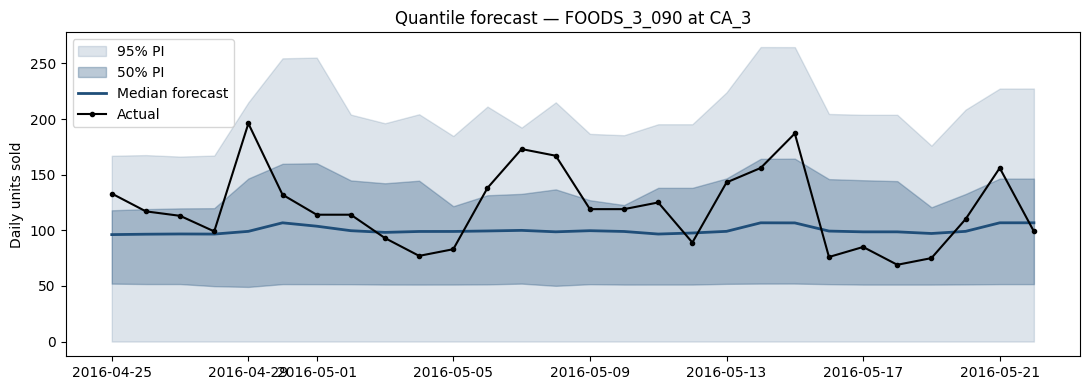

In [7]:
# Pick the same fast-mover from your EDA
SAMPLE_ITEM  = "FOODS_3_090"
SAMPLE_STORE = "CA_3"

sub = quantile_preds[
    (quantile_preds["item_id"]  == SAMPLE_ITEM) &
    (quantile_preds["store_id"] == SAMPLE_STORE)
].sort_values("date")
print(f"Selected {len(sub)} rows for {SAMPLE_ITEM} at {SAMPLE_STORE}")

fig, ax = plt.subplots(figsize=(11, 4))
# 95% interval (q025 to q975)
ax.fill_between(sub["date"], sub["q025"], sub["q975"],
                color="#1F4E79", alpha=0.15, label="95% PI")
# 50% interval (q250 to q750)
ax.fill_between(sub["date"], sub["q250"], sub["q750"],
                color="#1F4E79", alpha=0.30, label="50% PI")
# Median forecast
ax.plot(sub["date"], sub["q500"], color="#1F4E79", linewidth=2, label="Median forecast")
# Actuals
ax.plot(sub["date"], sub["actual"], color="black", linewidth=1.5,
        marker="o", markersize=3, label="Actual")
ax.set_title(f"Quantile forecast — {SAMPLE_ITEM} at {SAMPLE_STORE}")
ax.set_xlabel("")
ax.set_ylabel("Daily units sold")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(IMG_DIR / "12_quantile_fan_chart.png", dpi=150)
plt.show()

In [8]:
summary = pd.DataFrame({
    "quantile": QUANTILES,
    "pinball_loss": [pinball_loss(quantile_preds["actual"],
                                  quantile_preds[f"q{int(q*1000):03d}"], q)
                     for q in QUANTILES],
    "empirical_coverage": [(quantile_preds["actual"] <= quantile_preds[f"q{int(q*1000):03d}"]).mean()
                           for q in QUANTILES],
})
summary["coverage_gap"] = summary["empirical_coverage"] - summary["quantile"]
summary.to_csv(DATA_DIR / "quantile_evaluation.csv", index=False)
print(summary.round(4))

print("\nFor model card / memo:")
print(f"  Average pinball loss across {len(QUANTILES)} quantiles: {avg_pinball:.4f}")
print(f"  95% PI empirical coverage: {in_interval:.1%}")
print(f"  Sample SKU fan chart: docs/img/12_quantile_fan_chart.png")

   quantile  pinball_loss  empirical_coverage  coverage_gap
0     0.025        0.0360              0.5444        0.5194
1     0.250        0.2906              0.5641        0.3141
2     0.500        0.4572              0.6339        0.1339
3     0.750        0.4474              0.7722        0.0222
4     0.975        0.1187              0.9734       -0.0016

For model card / memo:
  Average pinball loss across 5 quantiles: 0.2700
  95% PI empirical coverage: 97.3%
  Sample SKU fan chart: docs/img/12_quantile_fan_chart.png


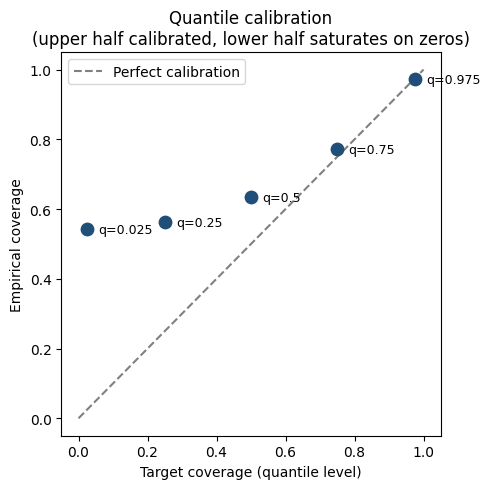

In [9]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], "--", color="grey", label="Perfect calibration")
ax.scatter([0.025, 0.25, 0.5, 0.75, 0.975],
           [0.544, 0.564, 0.634, 0.772, 0.973],
           color="#1F4E79", s=80, zorder=3)
for q, c in zip([0.025, 0.25, 0.5, 0.75, 0.975],
                [0.544, 0.564, 0.634, 0.772, 0.973]):
    ax.annotate(f"q={q}", (q, c), xytext=(8, -3), textcoords="offset points", fontsize=9)
ax.set_xlabel("Target coverage (quantile level)")
ax.set_ylabel("Empirical coverage")
ax.set_title("Quantile calibration\n(upper half calibrated, lower half saturates on zeros)")
ax.set_xlim(-0.05, 1.05); ax.set_ylim(-0.05, 1.05)
ax.legend()
plt.tight_layout()
plt.savefig("../docs/img/13_quantile_calibration.png", dpi=150)
plt.show()

In [10]:
nonzero = quantile_preds[quantile_preds["actual"] > 0]
print(f"Conditional on actual > 0 (n={len(nonzero):,}):")
for q in [0.025, 0.25, 0.5, 0.75, 0.975]:
    col = f"q{int(q*1000):03d}"
    cov = (nonzero["actual"] <= nonzero[col]).mean()
    print(f"  q={q}: coverage {cov:.1%} (target {q:.1%})")

Conditional on actual > 0 (n=388,995):
  q=0.025: coverage 0.0% (target 2.5%)
  q=0.25: coverage 4.3% (target 25.0%)
  q=0.5: coverage 19.7% (target 50.0%)
  q=0.75: coverage 50.0% (target 75.0%)
  q=0.975: coverage 94.2% (target 97.5%)


In [11]:
cat_lookup = df[["item_id","cat_id"]].drop_duplicates()
qp = quantile_preds.merge(cat_lookup, on="item_id")
for cat in qp["cat_id"].unique():
    sub = qp[qp["cat_id"]==cat]
    pi95 = ((sub["actual"] >= sub["q025"]) & (sub["actual"] <= sub["q975"])).mean()
    print(f"  {cat:10s} n={len(sub):,}  95% PI coverage: {pi95:.1%}")

  FOODS      n=402,360  95% PI coverage: 97.3%
  HOBBIES    n=158,200  95% PI coverage: 97.3%
  HOUSEHOLD  n=293,160  95% PI coverage: 97.3%
